# Model 1: peak acceleration on one axis

One number per 3 s window: the peak of `ay` (max |ay − mean|).
Each class is a bell curve (Gaussian) with its own mean and spread. A new
window gets the class whose curve is highest at its peak.

1. Load and trim recordings
2. Window peaks
3. The model
4. Blocked 5-fold cross-validation
5. Fit on all data, plot, save `model1.json`

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
CLASSES = ["still", "bike", "walk", "run"]
AXIS = "ay"
FS = 50
WIN_S = 3.0
TRIM_S = 5.0                      # drop from the start and end of every recording
EXTRA_TRIM_S = {}                 # e.g. {"walk_01": 70.0} to drop a recording's start
N_BLOCKS = 5
MIN_SD = 0.01                     # floor on spread so still's tiny spread stays usable

## 1. Load and trim

In [2]:
recs = []   # (name, label, ay values)
for p in sorted(DATA_DIR.glob("*.csv")):
    df = pd.read_csv(p)
    t = (df.t_ms - df.t_ms.iloc[0]) / 1000.0
    start = TRIM_S + EXTRA_TRIM_S.get(p.stem, 0.0)
    keep = (t >= start) & (t <= t.iloc[-1] - TRIM_S)
    recs.append((p.stem, p.stem.rsplit("_", 1)[0], df.loc[keep, AXIS].to_numpy()))
    print(f"{p.stem:10s} {keep.sum() / FS:6.1f} s kept")

bike_01      69.2 s kept
bike_02      74.9 s kept
run_01       53.4 s kept
still_01    114.0 s kept
walk_01     275.4 s kept
walk_02      92.7 s kept


## 2. Window peaks

3 s windows with 50% overlap. Each recording is also split into 5 time blocks
for testing; windows that cross a block edge are dropped so no data is shared
between a training block and a test block.

In [3]:
def peak(x):
    return np.abs(x - x.mean()).max()


n = int(WIN_S * FS)
rows = []
for name, label, x in recs:
    block_of = np.arange(len(x)) * N_BLOCKS // len(x)
    for i in range(0, len(x) - n + 1, n // 2):
        if block_of[i] != block_of[i + n - 1]:
            continue
        rows.append({"rec": name, "label": label, "block": block_of[i], "peak": peak(x[i:i + n])})
win = pd.DataFrame(rows)
win.groupby("label").size().reindex(CLASSES)

label
still     67
bike      77
walk     226
run       26
dtype: int64

## 3. The model

Training: mean and spread of the peak for each class.
Predicting: for each class, how likely is this peak under its bell curve?
Pick the most likely one. All classes count equally, even though walk has more
windows.

In [4]:
def fit(df):
    g = df.groupby("label").peak
    return {c: {"mean": float(g.mean()[c]), "sd": max(float(g.std()[c]), MIN_SD)} for c in CLASSES}


def log_likelihood(model, peaks):
    """One column per class: log of the bell curve's height at each peak."""
    peaks = np.asarray(peaks, dtype=float)
    return np.column_stack([
        -np.log(model[c]["sd"]) - 0.5 * ((peaks - model[c]["mean"]) / model[c]["sd"]) ** 2
        for c in CLASSES
    ])


def predict(model, peaks):
    return np.array(CLASSES)[log_likelihood(model, peaks).argmax(axis=1)]

## 4. Blocked 5-fold cross-validation

Each round trains on 4 blocks from every recording and tests on the 5th.

In [5]:
win["pred"] = ""
for b in range(N_BLOCKS):
    test = win.block == b
    model = fit(win[~test])
    win.loc[test, "pred"] = predict(model, win.loc[test, "peak"])

acc = (win.pred == win.label).mean()
recall = (win.pred == win.label).groupby(win.label).mean().reindex(CLASSES)
print(f"Accuracy: {acc:.1%}")
print(f"Balanced accuracy (mean of per-class recall): {recall.mean():.1%}\n")
print("Recall per class (share of each class predicted correctly):")
print(recall.map("{:.1%}".format).to_string())

Accuracy: 84.1%
Balanced accuracy (mean of per-class recall): 92.2%

Recall per class (share of each class predicted correctly):
label
still    100.0%
bike      94.8%
walk      73.9%
run      100.0%


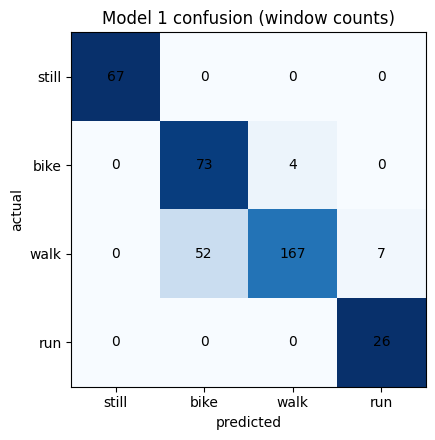

In [6]:
conf = pd.crosstab(win.label, win.pred).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(conf.div(conf.sum(axis=1), axis=0), cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, conf.iloc[i, j], ha="center", va="center")
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("Model 1 confusion (window counts)")
fig.tight_layout()

## 4b. Cross-session check

Bike and walk each have two recordings from different sessions. Train on one
session and test on the other, in both directions. Still and run (one
recording each) are always in training. This tests whether the model holds up
on a different day, which the blocked test can't.

In [7]:
def cross_session(train_rec, test_rec):
    pairs = {"bike": ("bike_01", "bike_02"), "walk": ("walk_01", "walk_02")}
    test_recs = [pairs[c][test_rec] for c in pairs]
    model = fit(win[~win.rec.isin(test_recs)])
    test = win[win.rec.isin(test_recs)]
    pred = predict(model, test.peak)
    print(f"Train on _0{train_rec + 1}, test on _0{test_rec + 1}:")
    for c in pairs:
        mask = (test.label == c).to_numpy()
        counts = pd.Series(pred[mask]).value_counts().reindex(CLASSES, fill_value=0)
        print(f"  {c:5s} recall {(pred[mask] == c).mean():.1%}   predicted as: {counts.to_dict()}")


cross_session(0, 1)
cross_session(1, 0)

Train on _01, test on _02:
  bike  recall 65.0%   predicted as: {'still': 0, 'bike': 26, 'walk': 14, 'run': 0}
  walk  recall 71.2%   predicted as: {'still': 0, 'bike': 11, 'walk': 37, 'run': 4}
Train on _02, test on _01:
  bike  recall 86.5%   predicted as: {'still': 0, 'bike': 32, 'walk': 5, 'run': 0}
  walk  recall 78.2%   predicted as: {'still': 0, 'bike': 36, 'walk': 136, 'run': 2}


## 5. Fit on all data

In [8]:
model = fit(win)
pd.DataFrame(model).T.round(3)

,mean,sd
still,0.020,0.015
bike,1.198,0.113
walk,1.619,0.414
run,3.540,0.544


In [9]:
# Decision boundaries: peaks where the predicted class changes
grid = np.linspace(0, win.peak.max() * 1.1, 5000)
pred = predict(model, grid)
change = np.nonzero(pred[1:] != pred[:-1])[0]
boundaries = [(float(grid[i]), pred[i], pred[i + 1]) for i in change]
for g, a, b in boundaries:
    print(f"{g:5.2f} g: {a} -> {b}")

 0.09 g: still -> walk
 0.94 g: walk -> bike
 1.39 g: bike -> walk
 2.48 g: walk -> run


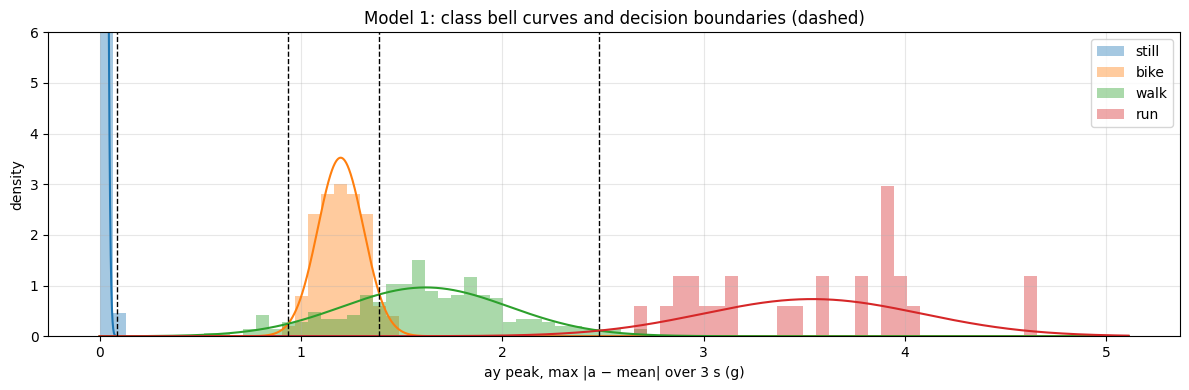

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
bins = np.linspace(0, grid[-1], 80)
colors = dict(zip(CLASSES, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
for c in CLASSES:
    ax.hist(win[win.label == c].peak, bins=bins, density=True, alpha=0.4, color=colors[c], label=c)
    m, s = model[c]["mean"], model[c]["sd"]
    curve = np.exp(-0.5 * ((grid - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
    ax.plot(grid, curve, color=colors[c], lw=1.5)
for g, _, _ in boundaries:
    ax.axvline(g, color="k", ls="--", lw=1)
ax.set_ylim(0, 6)   # still's curve is very tall; clip so the others are visible
ax.set_xlabel(f"{AXIS} peak, max |a − mean| over {WIN_S:.0f} s (g)")
ax.set_ylabel("density")
ax.set_title("Model 1: class bell curves and decision boundaries (dashed)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

In [11]:
out = {
    "axis": AXIS,
    "fs": FS,
    "window_s": WIN_S,
    "feature": "max |a - mean| over the window",
    "classes": model,
    "boundaries": [{"at": round(g, 3), "below": a, "above": b} for g, a, b in boundaries],
    "cv": {"accuracy": round(float(acc), 3),
           "recall": {c: round(float(recall[c]), 3) for c in CLASSES}},
}
Path("model1.json").write_text(json.dumps(out, indent=2))
print(json.dumps(out, indent=2))

{
  "axis": "ay",
  "fs": 50,
  "window_s": 3.0,
  "feature": "max |a - mean| over the window",
  "classes": {
    "still": {
      "mean": 0.020482388059701487,
      "sd": 0.01458300757853745
    },
    "bike": {
      "mean": 1.1975403463203462,
      "sd": 0.11318083685097864
    },
    "walk": {
      "mean": 1.6194774041297935,
      "sd": 0.4142201389207825
    },
    "run": {
      "mean": 3.540401538461538,
      "sd": 0.544029154066198
    }
  },
  "boundaries": [
    {
      "at": 0.086,
      "below": "still",
      "above": "walk"
    },
    {
      "at": 0.937,
      "below": "walk",
      "above": "bike"
    },
    {
      "at": 1.39,
      "below": "bike",
      "above": "walk"
    },
    {
      "at": 2.482,
      "below": "walk",
      "above": "run"
    }
  ],
  "cv": {
    "accuracy": 0.841,
    "recall": {
      "still": 1.0,
      "bike": 0.948,
      "walk": 0.739,
      "run": 1.0
    }
  }
}
